Dataset Description:
The Iris Dataset contains measurements of iris flowers along with their corresponding species.

# IMPORT THE LIBRARIES

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import trim_mean, median_abs_deviation

%matplotlib inline
sns.set_style("whitegrid")

# DATA COLLECTION

In [ ]:
df = pd.read_csv("Iris.csv")
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


All feature columns are numerical, while the Species column is a three-class categorical variable. Hence, the dataset is suitable for exploratory data analysis and multi-class classification.

# EXPLORATORY DATA ANALYTICS

In [ ]:
df.shape

(150, 6)

The dataset contains 150 rows and 6 variable columns.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


To check for the data type of the variables

In [ ]:
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


The numerical features exhibit different ranges and levels of variability.
Petal measurements show greater variation than sepal measurements.
The summary provides a good overview of the central tendency and spread of the data.

In [ ]:
df["Species"].unique()

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

Displays the 3 unique categories in the Species column.

In [ ]:
df["Species"].value_counts()

Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: Species, dtype: int64

Counts the number of observations in each species.

In [ ]:
# Selecting only numerical columns (excluding Id)
numeric_columns = df.drop(columns=["Id"]).select_dtypes(include=['int64', 'float64']).columns

for col in numeric_columns:

    summary = pd.DataFrame({

        'Mean': [df[col].mean()],

        'Trimmed Mean': [trim_mean(df[col], 0.10)],

        'Weighted Mean': [np.average(df[col])],

        'Median': [df[col].median()],

        'Minimum': [df[col].min()],

        'Maximum': [df[col].max()],

        'Variance': [df[col].var()],

        'Std Dev': [df[col].std()],

        'Q1': [df[col].quantile(0.25)],

        'Q2': [df[col].quantile(0.50)],

        'Q3': [df[col].quantile(0.75)],

        'IQR': [df[col].quantile(0.75) - df[col].quantile(0.25)],

        '10th Percentile': [df[col].quantile(0.10)],

        '25th Percentile': [df[col].quantile(0.25)],

        '50th Percentile': [df[col].quantile(0.50)],

        '75th Percentile': [df[col].quantile(0.75)],

        '90th Percentile': [df[col].quantile(0.90)],

        'MAD': [median_abs_deviation(df[col])]

    })

    print(f"\nSummary Statistics for {col}\n")
    display(summary)


Summary Statistics for SepalLengthCm



,Mean,Trimmed Mean,Weighted Mean,Median,Minimum,Maximum,Variance,Std Dev,Q1,Q2,Q3,IQR,10th Percentile,25th Percentile,50th Percentile,75th Percentile,90th Percentile,MAD
0,5.843333,5.808333,5.843333,5.8,4.3,7.9,0.685694,0.828066,5.1,5.8,6.4,1.3,4.8,5.1,5.8,6.4,6.9,0.7



Summary Statistics for SepalWidthCm



,Mean,Trimmed Mean,Weighted Mean,Median,Minimum,Maximum,Variance,Std Dev,Q1,Q2,Q3,IQR,10th Percentile,25th Percentile,50th Percentile,75th Percentile,90th Percentile,MAD
0,3.054,3.039167,3.054,3.0,2.0,4.4,0.188004,0.433594,2.8,3.0,3.3,0.5,2.5,2.8,3.0,3.3,3.61,0.25



Summary Statistics for PetalLengthCm



,Mean,Trimmed Mean,Weighted Mean,Median,Minimum,Maximum,Variance,Std Dev,Q1,Q2,Q3,IQR,10th Percentile,25th Percentile,50th Percentile,75th Percentile,90th Percentile,MAD
0,3.758667,3.760833,3.758667,4.35,1.0,6.9,3.113179,1.76442,1.6,4.35,5.1,3.5,1.4,1.6,4.35,5.1,5.8,1.25



Summary Statistics for PetalWidthCm



,Mean,Trimmed Mean,Weighted Mean,Median,Minimum,Maximum,Variance,Std Dev,Q1,Q2,Q3,IQR,10th Percentile,25th Percentile,50th Percentile,75th Percentile,90th Percentile,MAD
0,1.198667,1.184167,1.198667,1.3,0.1,2.5,0.582414,0.763161,0.3,1.3,1.8,1.5,0.2,0.3,1.3,1.8,2.2,0.7


SepalLengthCm:
The mean and median are very close, indicating that the distribution is approximately symmetric.
The trimmed mean is nearly equal to the mean, suggesting that extreme values have little influence on the data.
The standard deviation indicates moderate variability in sepal length among the flowers.
The IQR shows that the middle 50% of the observations are concentrated within a relatively narrow range.
The minimum and maximum indicate a reasonable spread without extreme values.
The MAD is relatively small, showing that most observations are close to the median.
Hence, Sepal Length is fairly evenly distributed with moderate variation and no significant effect of extreme values.

SepalWidthCm:
The mean and median are close, indicating only slight skewness.
The trimmed mean is very similar to the mean, showing that outliers have minimal impact.
The standard deviation suggests moderate variability in sepal width.
The IQR indicates that most flowers have sepal widths within a compact range.
The minimum and maximum show a moderate spread.
The MAD is low, indicating limited deviation from the median.
Hence, Sepal Width is moderately distributed with a few possible outliers, but most values are concentrated around the center.

PetalLengthCm:
The mean is slightly lower than the median because the small petal lengths of Iris-setosa influence the average.
The trimmed mean differs slightly from the mean, indicating the presence of distinct groups rather than extreme outliers.
The standard deviation is relatively high, reflecting considerable variation among the three species.
The IQR is wide, showing that petal length varies substantially.
The minimum and maximum indicate a broad range of values.
The MAD confirms noticeable variability around the median.
Hence, Petal Length shows high variability and is one of the most important features for distinguishing iris species.

PetalWidthCm
The mean and median are close, indicating a fairly balanced distribution.
The trimmed mean is almost identical to the mean, suggesting that extreme values do not significantly affect the distribution.
The standard deviation indicates substantial variation in petal width.
The IQR shows that the middle 50% of values cover a relatively wide range.
The minimum and maximum demonstrate a broad spread across species.
The MAD indicates moderate dispersion around the median.
Hence, Petal Width varies considerably among species and is one of the strongest features for iris species classification.

# CORRELATION MATRIX

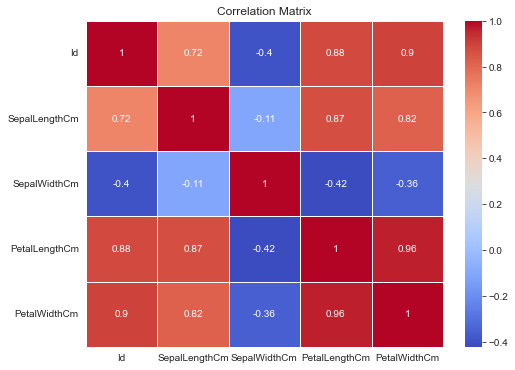

In [ ]:
plt.figure(figsize=(8,6))

corr_matrix = df.drop("Species", axis=1).corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

Petal Length and Petal Width exhibit a very strong positive correlation.
Sepal Length has a moderate positive correlation with petal measurements.
Sepal Width has a weak negative correlation with petal measurements.
Petal-related features are the most useful for distinguishing iris species.

# BOX PLOT

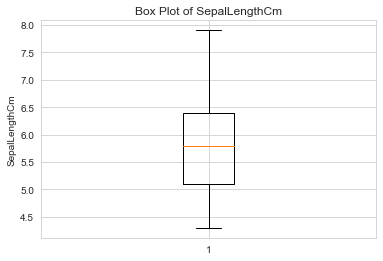

SepalLengthCm
Minimum      : 4.3
Q1           : 5.1
Median       : 5.8
Q3           : 6.4
Maximum      : 7.9
IQR          : 1.3000000000000007
Lower Fence  : 3.1499999999999986
Upper Fence  : 8.350000000000001
Outliers     : 0

------------------------------------------------------------



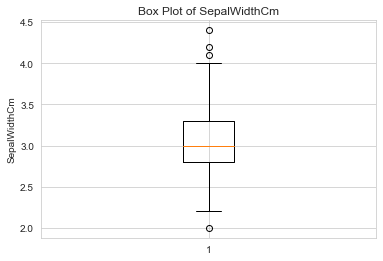

SepalWidthCm
Minimum      : 2.0
Q1           : 2.8
Median       : 3.0
Q3           : 3.3
Maximum      : 4.4
IQR          : 0.5
Lower Fence  : 2.05
Upper Fence  : 4.05
Outliers     : 4
Outlier Values:
[4.4 4.1 4.2 2. ]

------------------------------------------------------------



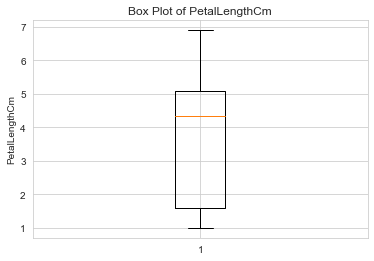

PetalLengthCm
Minimum      : 1.0
Q1           : 1.6
Median       : 4.35
Q3           : 5.1
Maximum      : 6.9
IQR          : 3.4999999999999996
Lower Fence  : -3.649999999999999
Upper Fence  : 10.349999999999998
Outliers     : 0

------------------------------------------------------------



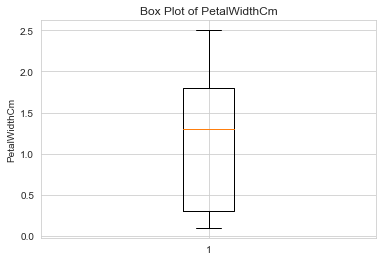

PetalWidthCm
Minimum      : 0.1
Q1           : 0.3
Median       : 1.3
Q3           : 1.8
Maximum      : 2.5
IQR          : 1.5
Lower Fence  : -1.95
Upper Fence  : 4.05
Outliers     : 0

------------------------------------------------------------



In [ ]:
# Selecting only numerical feature columns (excluding Id)
numeric_columns = df.drop(columns=["Id"]).select_dtypes(include=['int64', 'float64']).columns

for col in numeric_columns:

    plt.figure(figsize=(6,4))
    plt.boxplot(df[col])
    plt.title(f"Box Plot of {col}")
    plt.ylabel(col)
    plt.show()

    # Five-number summary
    Q1 = df[col].quantile(0.25)
    Median = df[col].median()
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}")
    print(f"Minimum      : {df[col].min()}")
    print(f"Q1           : {Q1}")
    print(f"Median       : {Median}")
    print(f"Q3           : {Q3}")
    print(f"Maximum      : {df[col].max()}")
    print(f"IQR          : {IQR}")
    print(f"Lower Fence  : {lower}")
    print(f"Upper Fence  : {upper}")
    print(f"Outliers     : {len(outliers)}")

    if len(outliers) > 0:
        print("Outlier Values:")
        print(outliers[col].values)

    print("\n" + "-"*60 + "\n")

SepalLengthCm: The feature has a moderate spread with no significant outliers.

SepalWidthCm: A few outliers are observed beyond the whiskers while most observations lie within the interquartile range.

PetalLengthCm: The feature exhibits a wide range due to differences among the three species. No significant outliers are present.

PetalWidthCm: The distribution has a broad spread with no major outliers. Petal width varies considerably across species.

Only SepalWidthCm contains noticeable outliers, while the remaining features are relatively free from extreme values.

# PAIR PLOT

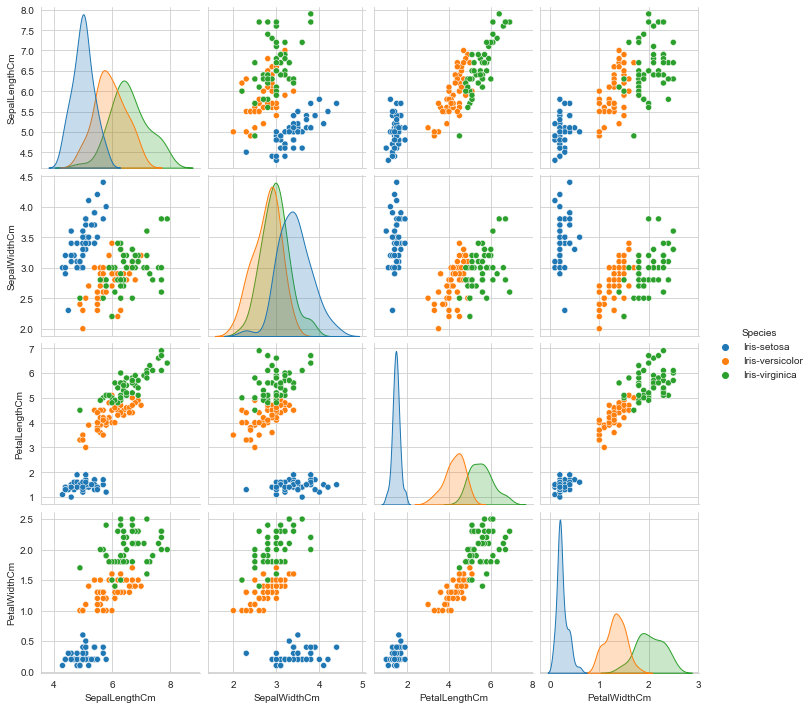

In [ ]:
sns.pairplot(df.drop(columns=["Id"]), hue="Species")
plt.show()

All three species occur with equal frequency.
The balanced class distribution is beneficial for classification algorithms.

# HISTOGRAM

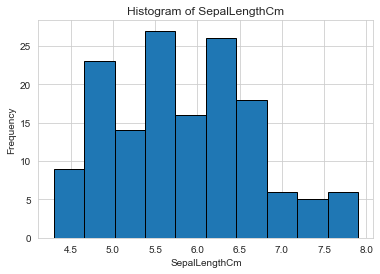

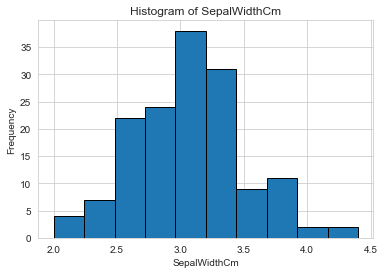

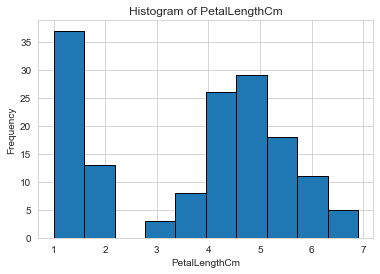

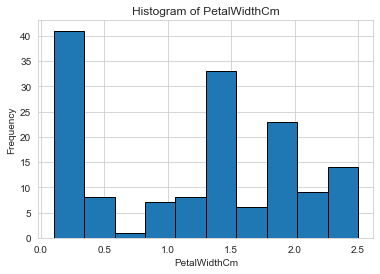

In [ ]:
# Selecting only numerical columns (excluding Id)
numeric_columns = df.drop(columns=["Id"]).select_dtypes(include=['int64', 'float64']).columns

for col in numeric_columns:

    plt.figure(figsize=(6,4))

    plt.hist(df[col], bins=10, edgecolor='black')

    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

SepalLengthCm: The distribution is approximately normal, with most observations between 5 cm and 7 cm.

SepalWidthCm: Most values are concentrated around 3 cm, with slight skewness.

PetalLengthCm: The histogram displays multiple peaks corresponding to the three iris species.

PetalWidthCm: The distribution also exhibits multiple peaks, indicating clear differences among species.

Petal features show better separation among species than sepal features.

# DENSITY PLOT

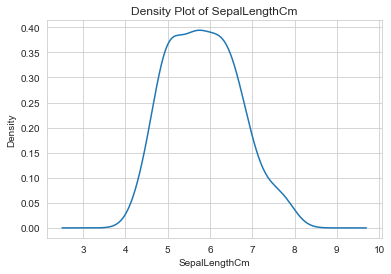

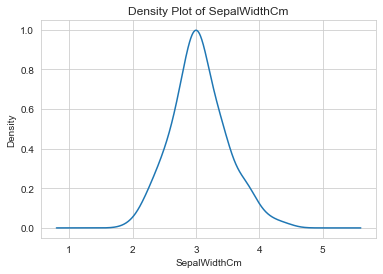

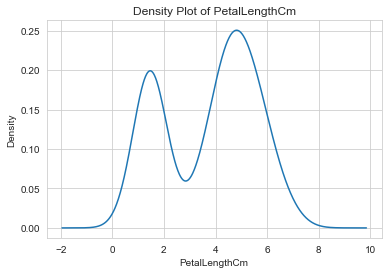

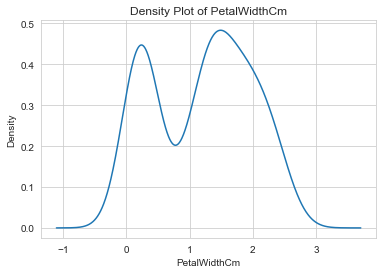

In [ ]:
# Selecting only numerical columns (excluding Id)
numeric_columns = df.drop(columns=["Id"]).select_dtypes(include=['int64', 'float64']).columns

for col in numeric_columns:

    plt.figure(figsize=(6,4))

    df[col].plot(kind='density')

    plt.title(f"Density Plot of {col}")
    plt.xlabel(col)

    plt.show()

SepalLengthCm: The density is concentrated around the central values, indicating a relatively symmetric distribution.

SepalWidthCm: The density shows slight skewness with most values around 3 cm.

PetalLengthCm: Multiple density peaks indicate clear differences among species.

PetalWidthCm: Multiple peaks are visible, reflecting variation among the three species.

Petal measurements provide better discrimination among iris species than sepal measurements.

# SCATTER PLOT

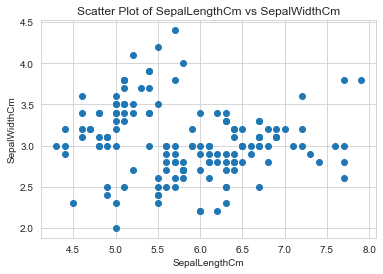

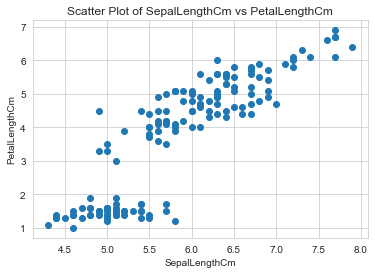

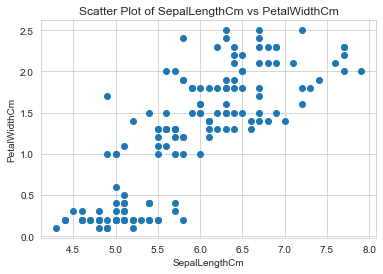

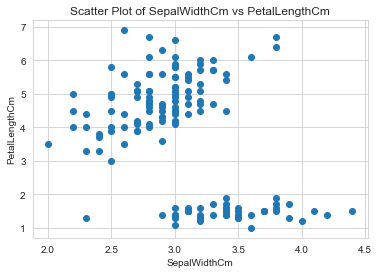

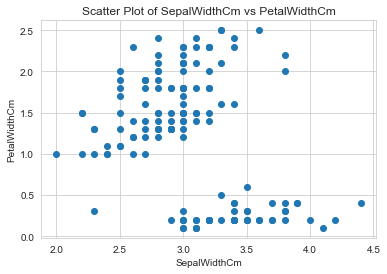

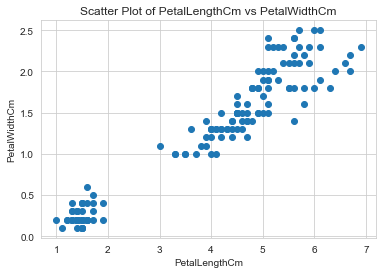

In [ ]:
# Selecting only numerical columns (excluding Id)
numeric_columns = df.drop(columns=["Id"]).select_dtypes(include=['int64', 'float64']).columns

# Scatter plots for every pair of numerical features
for i in range(len(numeric_columns)):
    for j in range(i + 1, len(numeric_columns)):

        plt.figure(figsize=(6,4))

        plt.scatter(df[numeric_columns[i]], df[numeric_columns[j]])

        plt.title(f"Scatter Plot of {numeric_columns[i]} vs {numeric_columns[j]}")
        plt.xlabel(numeric_columns[i])
        plt.ylabel(numeric_columns[j])

        plt.show()

SepalLengthCm vs SepalWidthCm: A weak relationship exists between the two sepal measurements.

SepalLengthCm vs PetalLengthCm: A positive relationship is observed.

SepalLengthCm vs PetalWidthCm: A moderate positive relationship exists.

SepalWidthCm vs PetalLengthCm: A weak negative relationship is observed.

SepalWidthCm vs PetalWidthCm: The relationship is weak.

PetalLengthCm vs PetalWidthCm: A strong positive relationship exists, making these features effective for species classification.

*SUMMARY OF EDA*

No missing (null) values are present in the dataset, indicating that the data is complete and does not require missing value treatment.
All predictor variables (SepalLengthCm, SepalWidthCm, PetalLengthCm, and PetalWidthCm) are numerical, while Species is a categorical variable with three classes.
The mean and median of most numerical features are close, indicating that the distributions are approximately symmetric with only slight skewness.
The box plots reveal a few outliers in SepalWidthCm, while the remaining numerical features do not exhibit significant outliers.
The dataset is perfectly balanced, with 50 observations for each of the three iris species, reducing the risk of class imbalance.
Correlation analysis indicates that PetalLengthCm and PetalWidthCm have the strongest positive correlation, making them highly informative features.
Species-wise analysis shows that Iris-virginica generally has the largest average petal and sepal measurements, Iris-setosa has the smallest, and Iris-versicolor has intermediate values.
Histograms, density plots, and scatter plots demonstrate that petal measurements provide better separation among species than sepal measurements.
The dataset is clean, balanced, and well-suited for exploratory data analysis, visualization, and multi-class classification tasks.